In [74]:
import pandas as pd
import numpy as np

In [75]:
df = pd.read_csv("customer_churn.csv")


In [76]:
df.head()

,age,tenure_months,monthly_charges,support_calls,contract_months,churn
0,56,15,2263,0,1,0
1,69,64,542,7,12,0
2,46,28,1443,4,6,0
3,32,39,2890,2,6,1
4,60,57,1849,10,12,1


In [77]:
df["churn"].value_counts(normalize=True)

,proportion
churn,
1,0.594
0,0.406


In [78]:
df.shape

(1000, 6)

In [79]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   age              1000 non-null   int64
 1   tenure_months    1000 non-null   int64
 2   monthly_charges  1000 non-null   int64
 3   support_calls    1000 non-null   int64
 4   contract_months  1000 non-null   int64
 5   churn            1000 non-null   int64
dtypes: int64(6)
memory usage: 47.0 KB


In [80]:
df.isnull().sum()

,0
age,0
tenure_months,0
monthly_charges,0
support_calls,0
contract_months,0
churn,0


In [81]:
df.describe()

,age,tenure_months,monthly_charges,support_calls,contract_months,churn
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,43.81900,36.083000,1780.715000,4.909000,10.554000,0.59400
std,14.99103,20.778302,720.988454,3.180697,8.410102,0.49133
min,18.00000,1.000000,501.000000,0.000000,1.000000,0.00000
25%,31.00000,18.000000,1150.500000,2.000000,6.000000,0.00000
50%,44.00000,36.000000,1792.000000,5.000000,6.000000,1.00000
75%,56.00000,54.000000,2400.250000,8.000000,12.000000,1.00000
max,69.00000,72.000000,3000.000000,10.000000,24.000000,1.00000


In [82]:
df["churn"].value_counts()

,count
churn,
1,594
0,406


In [83]:
df["churn"].value_counts(normalize=True) * 100

,proportion
churn,
1,59.4
0,40.6


In [84]:
import matplotlib.pyplot as plt

<Axes: xlabel='churn'>

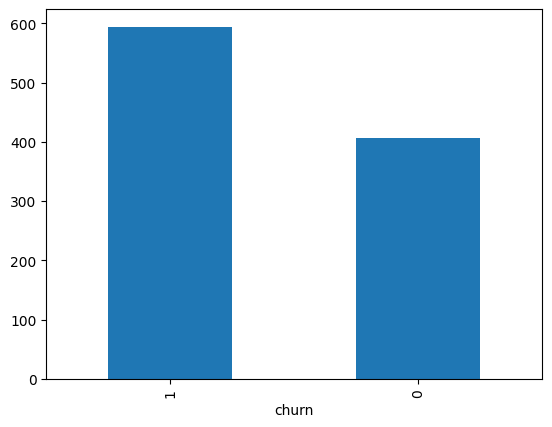

In [85]:
df["churn"].value_counts().plot(kind = "bar")

In [86]:
import seaborn as sns

<Axes: xlabel='churn', ylabel='support_calls'>

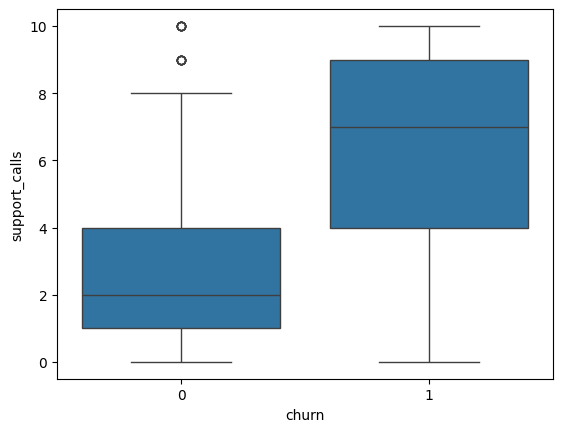

In [87]:
sns.boxplot(
    x="churn",
    y="support_calls",
    data = df

)

<Axes: xlabel='churn', ylabel='monthly_charges'>

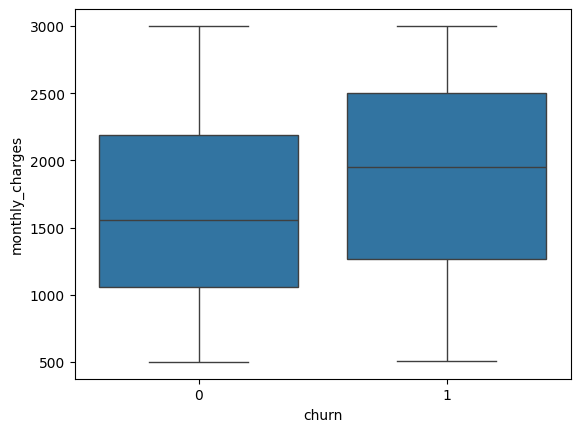

In [88]:
sns.boxplot(
    x = "churn",
    y = "monthly_charges",
    data = df
)

In [89]:
correlation = df.corr()
correlation

,age,tenure_months,monthly_charges,support_calls,contract_months,churn
age,1.000000,-0.041214,-0.036672,-0.074011,-0.018227,-0.028742
tenure_months,-0.041214,1.000000,-0.062143,0.026756,-0.028504,-0.359582
monthly_charges,-0.036672,-0.062143,1.000000,0.048457,-0.011824,0.169107
support_calls,-0.074011,0.026756,0.048457,1.000000,0.056446,0.538719
contract_months,-0.018227,-0.028504,-0.011824,0.056446,1.000000,-0.069786
churn,-0.028742,-0.359582,0.169107,0.538719,-0.069786,1.000000


In [90]:
X = df[
    [
        "age",
        "tenure_months",
        "monthly_charges",
        "support_calls",
        "contract_months"
    ]
]

y = df["churn"]

In [91]:
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.2, random_state=42)

In [92]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()



In [93]:
scaler.fit(X_train)

StandardScaler()

In [94]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [95]:
X_train.head()

,age,tenure_months,monthly_charges,support_calls,contract_months
29,42,53,2192,3,24
535,22,41,1669,0,24
695,65,24,2401,7,12
557,29,67,2671,3,1
836,54,58,1836,6,1


In [96]:
X_train_scaled[:5]

array([[-0.12149869,  0.79611794,  0.57859194, -0.63732773,  1.58607224],
       [-1.4818759 ,  0.21738613, -0.14540287, -1.58679177,  1.58607224],
       [ 1.4429351 , -0.60248392,  0.867913  ,  0.62862431,  0.16729722],
       [-1.00574387,  1.47130504,  1.24167705, -0.63732773, -1.13324654],
       [ 0.69472764,  1.03725619,  0.08577712,  0.3121363 , -1.13324654]])

In [97]:
from sklearn.linear_model import LogisticRegression

In [98]:
model = LogisticRegression()

model.fit(X_train_scaled , y_train)

LogisticRegression()

In [99]:
prediction = model.predict(X_test_scaled)

# prediction = model.predict_proba(X_test_scaled)

In [100]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test , prediction)

cm

array([[67, 19],
       [20, 94]])

In [101]:
import seaborn as sns
import matplotlib.pyplot as plt

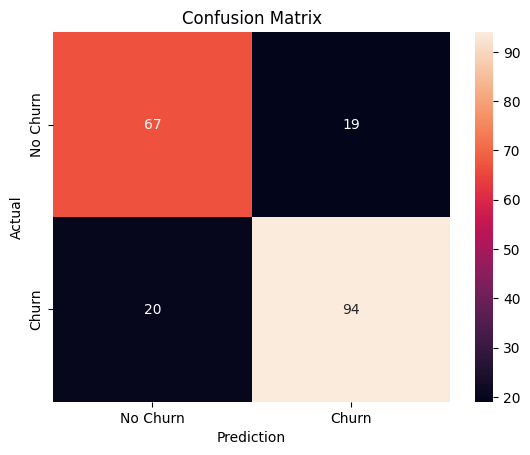

In [102]:
sns.heatmap(
    cm ,
    annot = True,
    xticklabels = ["No Churn" , "Churn"],
    yticklabels = ["No Churn" , "Churn"],
)

plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [105]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test , prediction)

accuracy

0.805

In [108]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

cm = confusion_matrix(y_test, prediction)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy :", accuracy_score(y_test, prediction))
print("Precision:", precision_score(y_test, prediction))
print("Recall   :", recall_score(y_test, prediction))
print("F1 Score :", f1_score(y_test, prediction))

Confusion Matrix:
[[67 19]
 [20 94]]

Accuracy : 0.805
Precision: 0.831858407079646
Recall   : 0.8245614035087719
F1 Score : 0.8281938325991189


In [110]:
import joblib

joblib.dump(model, "churn_model.pkl")

['churn_model.pkl']